# Growth-stage ablation for strawberry condition classification

This is the supplied notebook with stored outputs and a portable input path. Set `ABLATION_DATA_DIR` or edit `ROOT` to your data directory before running. The original extraction cell writes extracted files beside source ZIP archives. The standalone `ablation_test.py` uses already-extracted inputs and writes results to `--out`.

**Interpretation:** neither experiment establishes a meaningful gain from stage information. Intervals include zero and extend beyond the ±0.01 practical margin. The final cell's 0.60 threshold is a heuristic, not a statistical chance benchmark. The original figure's line labelled "Chance (0.5)" is a reference, not a calibrated chance test. See `README.md` and `docs/METHODS.md` for the distinction.

**Reproduction:** original feature caches are accepted by row count alone. Clear them if input rows, order or crops change. The portable script fingerprints newly generated caches.


In [1]:
import os, json, shutil, zipfile, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get("ABLATION_DATA_DIR", "data"))
OUT = Path("ablation_out")
OUT.mkdir(exist_ok=True)

CLASSES = ("잎끝마름", "황화")
STAGE_ORDER = ["정식기", "생육기", "출뢰기", "개화기", "과실비대기", "수확기"]
MIN_DELTA = 0.01  # smallest macro-F1 gain worth keeping stage for - decide now, before seeing results

plt.rcParams["font.family"] = "Malgun Gothic"  # Korean text in plots on Windows
plt.rcParams["axes.unicode_minus"] = False
print("ROOT exists:", ROOT.exists())

ROOT exists: True


In [2]:
#helper functions

def nfc(s):
    return unicodedata.normalize("NFC", s)


def member_name(info):
    name = info.filename
    if not info.flag_bits & 0x800:  # not UTF-8 -> AI Hub zips use cp949
        try:
            name = name.encode("cp437").decode("cp949")
        except (UnicodeEncodeError, UnicodeDecodeError):
            pass
    parts = [p for p in name.replace("\\", "/").split("/") if p not in ("", ".", "..") and not p.endswith(":")]
    return Path(*parts)


def extract(z):
    dest = z.with_suffix("")
    with zipfile.ZipFile(z) as zf:
        infos = [i for i in zf.infolist() if not i.filename.endswith(("/", "\\"))]
        if dest.exists() and sum(p.is_file() for p in dest.rglob("*")) >= len(infos):
            print("already extracted:", z.name)
            return
        print(f"extracting {z.name} ({len(infos):,} files)")
        for info in infos:
            out = dest / member_name(info)
            out.parent.mkdir(parents=True, exist_ok=True)
            with zf.open(info) as src, open(out, "wb") as dst:
                shutil.copyfileobj(src, dst, 1 << 20)


def read_json(p):
    for enc in ("utf-8", "utf-8-sig", "cp949"):
        try:
            with open(p, encoding=enc) as f:
                return json.load(f)
        except UnicodeDecodeError:
            continue
        except (json.JSONDecodeError, OSError):
            return None
    return None

In [3]:
#extract zips 
zips = [z for z in sorted(ROOT.rglob("*.zip"))
        if nfc(z.name)[:3] in ("VL_", "VS_") and any(c in nfc(z.name) for c in CLASSES)]
print(len(zips), "zips:", [z.name for z in zips])  # expect 4
for z in zips:
    extract(z)

4 zips: ['VS_01.딸기_001.설향_04.잎끝마름.zip', 'VS_01.딸기_001.설향_05.황화.zip', 'VL_01.딸기_001.설향_04.잎끝마름.zip', 'VL_01.딸기_001.설향_05.황화.zip']
already extracted: VS_01.딸기_001.설향_04.잎끝마름.zip
already extracted: VS_01.딸기_001.설향_05.황화.zip
already extracted: VL_01.딸기_001.설향_04.잎끝마름.zip
already extracted: VL_01.딸기_001.설향_05.황화.zip


In [4]:
#labels, image matching, and plant coverage
KEYS = {"growth_stage": "stage", "disease_class": "label", "farm_id": "farm",
        "crops_id": "plant", "fname": "fname"}
rows = []
for jp in ROOT.rglob("*.json"):
    d = read_json(jp)
    if d is None:
        continue
    im = d.get("images", {})
    rows.append({new: str(im.get(old) or "").strip() for old, new in KEYS.items()})
df = pd.DataFrame(rows)
df["stage"] = df.stage.replace({"출뢰": "출뢰기"})
df["group"] = df.farm + "_" + df.plant  # one plant = one group

img_paths = {nfc(fn).lower(): os.path.join(dp, fn)
             for dp, _, fns in os.walk(ROOT) for fn in fns
             if fn.lower().endswith((".jpg", ".jpeg", ".png"))}
df["image_path"] = df.fname.map(lambda f: img_paths.get(nfc(f).lower()))

data = df[df.label.isin(CLASSES) & (df.stage != "") & df.image_path.notna()].reset_index(drop=True)
stages = [s for s in STAGE_ORDER if s in set(data.stage)]
data.to_csv(OUT / "data.csv", index=False, encoding="utf-8-sig")
print(f"{len(df):,} labels read, {len(data):,} usable images, farms: {list(data.farm.unique())}")
print(data.groupby("label").group.nunique().rename("plants").to_string())
data.groupby(["stage", "label"]).group.nunique().unstack().reindex(stages)  # plants per stage x class

3,540 labels read, 3,503 usable images, farms: ['AI22_003']
label
잎끝마름    33
황화      22


label,잎끝마름,황화
stage,,
정식기,18,13
출뢰기,28,16
개화기,14,10
과실비대기,27,22
수확기,28,19


In [5]:
#image features on CPU
import torch
import timm
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
torch.set_num_threads(os.cpu_count())


def load(p):
    im = Image.open(p)
    im.draft("RGB", (448, 448))  # fast reduced-size JPEG decode
    return im.convert("RGB")


feat_file = OUT / "features.npy"
if feat_file.exists() and len(np.load(feat_file)) == len(data):
    X = np.load(feat_file)
    print("loaded cached features")
else:
    model = timm.create_model("convnext_tiny.fb_in22k", pretrained=True, num_classes=0).eval()
    tf = timm.data.create_transform(**timm.data.resolve_model_data_config(model))
    chunks = []
    with torch.inference_mode():
        for i in range(0, len(data), 32):
            x = torch.stack([tf(load(p)) for p in data.image_path[i:i + 32]])
            chunks.append(model(x).numpy())
            if i % 320 == 0:
                print(f"{i:,}/{len(data):,}")
    X = np.concatenate(chunks)
    np.save(feat_file, X)
print(X.shape)

loaded cached features
(3503, 768)


In [6]:
#cross-validated ablation 
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

y = (data.label == CLASSES[1]).astype(int).values  # 0 = 잎끝마름, 1 = 황화
s = data.stage.map({st: k for k, st in enumerate(stages)}).values
S = np.eye(len(stages))[s]
groups = data.group.values


def design(Z, St, arm):
    if arm == "stage_only":
        return St
    if arm == "no_stage":
        return Z
    if arm == "stage_additive":
        return np.hstack([Z, St])
    return np.hstack([Z, St] + [Z * St[:, [k]] for k in range(St.shape[1])])  # stage_interaction


ARMS = ["stage_only", "no_stage", "stage_additive", "stage_interaction"]
ALL_ARMS = ARMS + ["stage_additive_shuffled", "stage_interaction_shuffled"]
REPEATS, FOLDS, PCA_DIM = 5, 5, 64

P = {a: np.zeros((REPEATS, len(y))) for a in ALL_ARMS}
for r in range(REPEATS):
    rng = np.random.default_rng(r)
    cv = StratifiedGroupKFold(n_splits=FOLDS, shuffle=True, random_state=r)
    for tr, te in cv.split(X, y, groups):
        prep = make_pipeline(StandardScaler(), PCA(PCA_DIM, random_state=0), StandardScaler()).fit(X[tr])
        Ztr, Zte = prep.transform(X[tr]), prep.transform(X[te])
        Ste_shuf = S[te][rng.permutation(len(te))]  # stage scrambled at test time
        for arm in ARMS:
            clf = LogisticRegression(C=0.5, max_iter=5000, class_weight="balanced")
            clf.fit(design(Ztr, S[tr], arm), y[tr])
            P[arm][r, te] = clf.predict_proba(design(Zte, S[te], arm))[:, 1]
            if arm in ("stage_additive", "stage_interaction"):
                P[arm + "_shuffled"][r, te] = clf.predict_proba(design(Zte, Ste_shuf, arm))[:, 1]
    print(f"repeat {r + 1}/{REPEATS} done")

pred = {a: (P[a].mean(0) >= 0.5).astype(int) for a in ALL_ARMS}  # average over repeats

repeat 1/5 done
repeat 2/5 done
repeat 3/5 done
repeat 4/5 done
repeat 5/5 done


In [7]:
#bootstrap by plant 
def macro_f1(yt, yp):
    f = [2 * np.sum((yp == c) & (yt == c)) / (np.sum(yp == c) + np.sum(yt == c))
         for c in (0, 1) if np.any(yt == c)]
    return np.mean(f)


ug, ginv = np.unique(groups, return_inverse=True)
idx_by_plant = [np.where(ginv == g)[0] for g in range(len(ug))]
rng = np.random.default_rng(0)
B = 2000
boot = {a: np.empty(B) for a in ALL_ARMS}
boot_stage = {a: np.full((B, len(stages)), np.nan) for a in ALL_ARMS}
for b in range(B):
    idx = np.concatenate([idx_by_plant[g] for g in rng.integers(0, len(ug), len(ug))])  # resample plants
    yb, sb = y[idx], s[idx]
    for a in ALL_ARMS:
        pb = pred[a][idx]
        boot[a][b] = macro_f1(yb, pb)
        for k in range(len(stages)):
            m = sb == k
            if m.any():
                boot_stage[a][b, k] = macro_f1(yb[m], pb[m])

In [8]:
#results and discussion 

def ci(x, level=0.95):
    tail = (1 - level) / 2*100
    return np.nanpercentile(x, [tail, 100 - tail]) 

def verdict(lo, hi, m=MIN_DELTA):
    if lo > m:
        return "HELPS"
    if lo > 0:
        return "helps, but maybe less than MIN_DELTA"
    if hi < -m:
        return "HURTS"
    if lo >= -m and hi <= m: 
        return "EQUIVALENT (no meaningful difference)"
    return "INCONCLUSIVE (CI too wide)"

overall = pd.DataFrame([(a, macro_f1(y, pred[a]), *ci(boot[a])) for a in ALL_ARMS],
                       columns =["arm", "macro_f1", "ci_lo", "ci_hi"])

MAIN = 1 - 0.05 / 2
comparisons = [("stage_additive", "no_stage", MAIN), 
               ("stage_interaction", "no_stage", MAIN), 
               ("stage_additive", "stage_additive_shuffled", 0.95),
               ("stage_interaction", "stage_interaction_shuffled", 0.95)]

rows = []
for a, b_, lev in comparisons:
    lo, hi = ci(boot[a] - boot[b_], lev)
    rows.append((f"{a} vs {b_}", macro_f1(y, pred[a]) - macro_f1(y, pred[b_]), lo, hi, verdict(lo, hi)))
deltas = pd.DataFrame(rows, columns=["comparison", "delta", "ci_lo", "ci_hi", "verdict"])

main, shuf = deltas.iloc[:2], deltas.iloc[2:]
if ((main.ci_lo.values > 0) & (shuf.ci_lo.values > 0)).any():
    decision = "KEEP stage conditioning: it improves held-out performance and the model uses it."
elif (main.ci_hi <= MIN_DELTA).all():
    decision = f"DROP stage conditioning: confidently no gain larger than {MIN_DELTA} macro-F1."
else:
    decision = "NO CONCLUSION YET: intervals too wide - add the TS_ training images and re-run."

overall.to_csv(OUT / "overall.csv", index=False)
deltas.to_csv(OUT / "deltas.csv", index=False, encoding="utf-8-sig")
display(overall.round(3))
display(deltas.round(3))
print("DECISION:", decision)


,arm,macro_f1,ci_lo,ci_hi
0,stage_only,0.501,0.446,0.551
1,no_stage,0.556,0.477,0.623
2,stage_additive,0.555,0.478,0.622
3,stage_interaction,0.554,0.481,0.614
4,stage_additive_shuffled,0.557,0.481,0.620
5,stage_interaction_shuffled,0.533,0.465,0.593


,comparison,delta,ci_lo,ci_hi,verdict
0,stage_additive vs no_stage,-0.001,-0.017,0.016,INCONCLUSIVE (CI too wide)
1,stage_interaction vs no_stage,-0.002,-0.048,0.043,INCONCLUSIVE (CI too wide)
2,stage_additive vs stage_additive_shuffled,-0.002,-0.019,0.014,INCONCLUSIVE (CI too wide)
3,stage_interaction vs stage_interaction_shuffled,0.021,-0.018,0.057,INCONCLUSIVE (CI too wide)


DECISION: NO CONCLUSION YET: intervals too wide - add the TS_ training images and re-run.


In [9]:
extra = []
for jp in ROOT.rglob("*.json"):
    d = read_json(jp)
    if d is None:
        continue
    im = d.get("images", {})
    a = (d.get("annotations") or [{}])[0]
    c = (d.get("categories") or [{}])[0]
    bx = a.get("bbox") or [0, 0, 0, 0]
    W, H = float(im.get("width") or 0), float(im.get("height") or 0)
    extra.append({"fname": str(im.get("fname") or "").strip(),
                  "status": a.get("disease_status", ""),
                  "part": c.get("name", ""),
                  "bbox_frac": bx[2] * bx[3] / (W * H) if W and H else np.nan})

d2 = data.merge(pd.DataFrame(extra), on="fname", how="left")
display(pd.crosstab(d2.status, d2.label, margins=True))
display(pd.crosstab(d2.part, d2.label))
display(d2.groupby("label").bbox_frac.describe().round(3))

for st in ("Y", "N"):
    m = (d2.status == st).values
    if m.any():
        print(f"no_stage macro-F1 on status={st}: {macro_f1(y[m], pred['no_stage'][m]):.3f}  (n={m.sum():,})")

label,잎끝마름,황화,All
status,,,
E,10,10,20
N,1865,1416,3281
Y,114,88,202
All,1989,1514,3503


label,잎끝마름,황화
part,,
과실,387,286
잎,1064,838
줄기,386,245
화방,152,145


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
잎끝마름,1989.0,0.020,0.020,0.0,0.006,0.014,0.030,0.140
황화,1514.0,0.021,0.021,0.0,0.006,0.014,0.028,0.139


no_stage macro-F1 on status=Y: 0.534  (n=202)
no_stage macro-F1 on status=N: 0.558  (n=3,281)


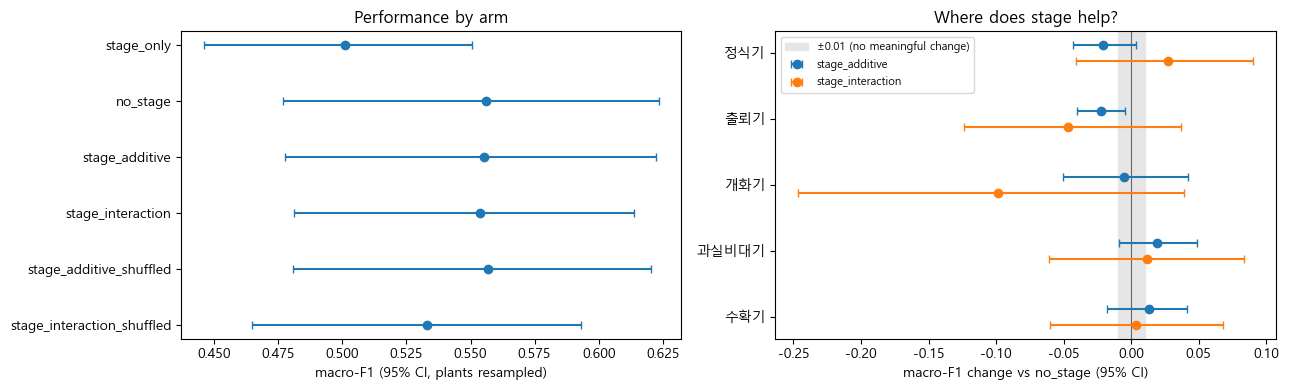

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

o = overall.iloc[::-1]
ax1.errorbar(o.macro_f1, range(len(o)), xerr=[o.macro_f1 - o.ci_lo, o.ci_hi - o.macro_f1],
             fmt="o", capsize=3)
ax1.set_yticks(range(len(o)), o.arm)
ax1.set_xlabel("macro-F1 (95% CI, plants resampled)")
ax1.set_title("Performance by arm")

yy = np.arange(len(stages))
ax2.axvspan(-MIN_DELTA, MIN_DELTA, color="0.9", label=f"±{MIN_DELTA} (no meaningful change)")
ax2.axvline(0, color="0.4", lw=0.8)
for off, a, col in ((-0.12, "stage_additive", "C0"), (0.12, "stage_interaction", "C1")):
    d = boot_stage[a] - boot_stage["no_stage"]
    point = [macro_f1(y[s == k], pred[a][s == k]) - macro_f1(y[s == k], pred["no_stage"][s == k])
             for k in range(len(stages))]
    lo, hi = np.nanpercentile(d, [2.5, 97.5], axis=0)
    ax2.errorbar(point, yy + off, xerr=[np.array(point) - lo, hi - np.array(point)],
                 fmt="o", color=col, capsize=3, label=a)
ax2.set_yticks(yy, stages)
ax2.invert_yaxis()
ax2.set_xlabel("macro-F1 change vs no_stage (95% CI)")
ax2.set_title("Where does stage help?")
ax2.legend(fontsize=8)

fig.tight_layout()
fig.savefig(OUT / "ablation_results.png", dpi=160)
plt.show()

In [11]:
#leaf images with their boxes 
meta = []
for jp in ROOT.rglob("*.json"):
    d = read_json(jp)
    if d is None:
        continue
    im = d.get("images", {})
    a = (d.get("annotations") or [{}])[0]
    c = (d.get("categories") or [{}])[0]
    meta.append({"fname": str(im.get("fname") or "").strip(),
                 "part": c.get("name", ""),
                 "bbox": a.get("bbox"),
                 "W": float(im.get("width") or 0),
                 "H": float(im.get("height") or 0)})
meta = pd.DataFrame(meta)

base = pd.read_csv(Path("ablation_out") / "data.csv")  # the original 3,503-image table
leaf = base.merge(meta, on="fname", how="left")
leaf = leaf[(leaf.part == "잎") & leaf.bbox.notna() & (leaf.W > 0)].reset_index(drop=True)
leaf_stages = [s for s in STAGE_ORDER if s in set(leaf.stage)]

print(f"{len(leaf):,} leaf images")
print(leaf.groupby("label").group.nunique().rename("plants").to_string())
leaf.groupby(["stage", "label"]).group.nunique().unstack().reindex(leaf_stages)

1,902 leaf images
label
잎끝마름    33
황화      22


label,잎끝마름,황화
stage,,
정식기,18,13
출뢰기,28,16
개화기,12,8
과실비대기,24,19
수확기,28,17


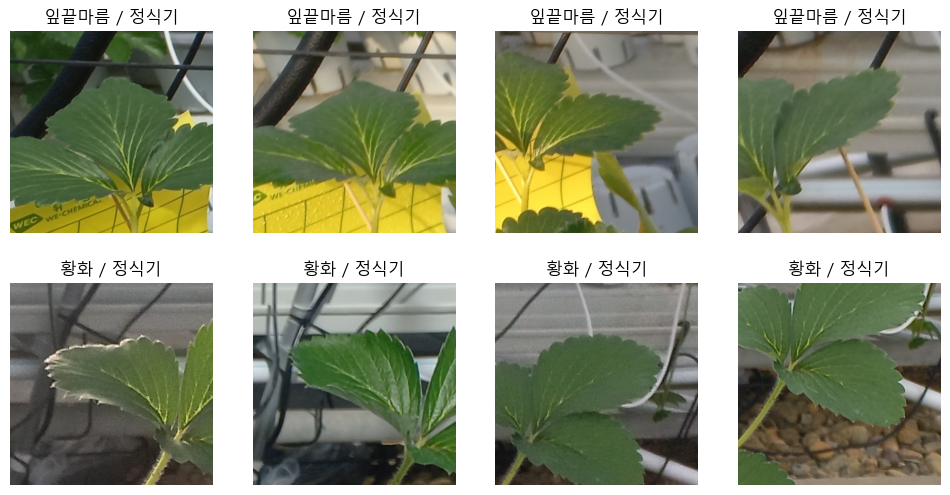

In [12]:
#check the crops look okay 
from PIL import ImageOps


def load_crop(row, pad=0.5):
    im = Image.open(row.image_path)
    if im.size != (int(row.W), int(row.H)):
        im = ImageOps.exif_transpose(im)  # photo stored rotated
    sx, sy = im.size[0] / row.W, im.size[1] / row.H  # photo stored at a different size
    x, y, w, h = row.bbox
    cx, cy = (x + w / 2) * sx, (y + h / 2) * sy
    side = max(w * sx, h * sy) * (1 + pad)
    return im.crop((cx - side / 2, cy - side / 2, cx + side / 2, cy + side / 2)).convert("RGB")


fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, r in zip(axes.flat, leaf.groupby("label").head(4).itertuples()):
    ax.imshow(load_crop(r))
    ax.set_title(f"{r.label} / {r.stage}")
    ax.axis("off")
plt.show()

In [13]:
#features from the crops 
crop_file = Path("ablation_out") / "features_leafcrop.npy"
if crop_file.exists() and len(np.load(crop_file)) == len(leaf):
    X_crop = np.load(crop_file)
    print("loaded cached crop features")
else:
    model = timm.create_model("convnext_tiny.fb_in22k", pretrained=True, num_classes=0).eval()
    tf = timm.data.create_transform(**timm.data.resolve_model_data_config(model))
    chunks = []
    with torch.inference_mode():
        for i in range(0, len(leaf), 32):
            x = torch.stack([tf(load_crop(r)) for r in leaf.iloc[i:i + 32].itertuples()])
            chunks.append(model(x).numpy())
            if i % 320 == 0:
                print(f"{i:,}/{len(leaf):,}")
    X_crop = np.concatenate(chunks)
    np.save(crop_file, X_crop)
print(X_crop.shape)

loaded cached crop features
(1902, 768)


In [14]:
#switch the notebook to the crop data
data, X, stages = leaf, X_crop, leaf_stages
OUT = Path("ablation_out_leafcrop")  # keep the first run's results separate
OUT.mkdir(exist_ok=True)
print(len(data), X.shape, stages)

1902 (1902, 768) ['정식기', '출뢰기', '개화기', '과실비대기', '수확기']


In [15]:
#cross-validated ablation 
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

y = (data.label == CLASSES[1]).astype(int).values  # 0 = 잎끝마름, 1 = 황화
s = data.stage.map({st: k for k, st in enumerate(stages)}).values
S = np.eye(len(stages))[s]
groups = data.group.values


def design(Z, St, arm):
    if arm == "stage_only":
        return St
    if arm == "no_stage":
        return Z
    if arm == "stage_additive":
        return np.hstack([Z, St])
    return np.hstack([Z, St] + [Z * St[:, [k]] for k in range(St.shape[1])])  # stage_interaction


ARMS = ["stage_only", "no_stage", "stage_additive", "stage_interaction"]
ALL_ARMS = ARMS + ["stage_additive_shuffled", "stage_interaction_shuffled"]
REPEATS, FOLDS, PCA_DIM = 5, 5, 64

P = {a: np.zeros((REPEATS, len(y))) for a in ALL_ARMS}
for r in range(REPEATS):
    rng = np.random.default_rng(r)
    cv = StratifiedGroupKFold(n_splits=FOLDS, shuffle=True, random_state=r)
    for tr, te in cv.split(X, y, groups):
        prep = make_pipeline(StandardScaler(), PCA(PCA_DIM, random_state=0), StandardScaler()).fit(X[tr])
        Ztr, Zte = prep.transform(X[tr]), prep.transform(X[te])
        Ste_shuf = S[te][rng.permutation(len(te))]  # stage scrambled at test time
        for arm in ARMS:
            clf = LogisticRegression(C=0.5, max_iter=5000, class_weight="balanced")
            clf.fit(design(Ztr, S[tr], arm), y[tr])
            P[arm][r, te] = clf.predict_proba(design(Zte, S[te], arm))[:, 1]
            if arm in ("stage_additive", "stage_interaction"):
                P[arm + "_shuffled"][r, te] = clf.predict_proba(design(Zte, Ste_shuf, arm))[:, 1]
    print(f"repeat {r + 1}/{REPEATS} done")

pred = {a: (P[a].mean(0) >= 0.5).astype(int) for a in ALL_ARMS}  # average over repeats

repeat 1/5 done
repeat 2/5 done
repeat 3/5 done
repeat 4/5 done
repeat 5/5 done


In [16]:
#bootstrap by plant 
def macro_f1(yt, yp):
    f = [2 * np.sum((yp == c) & (yt == c)) / (np.sum(yp == c) + np.sum(yt == c))
         for c in (0, 1) if np.any(yt == c)]
    return np.mean(f)


ug, ginv = np.unique(groups, return_inverse=True)
idx_by_plant = [np.where(ginv == g)[0] for g in range(len(ug))]
rng = np.random.default_rng(0)
B = 2000
boot = {a: np.empty(B) for a in ALL_ARMS}
boot_stage = {a: np.full((B, len(stages)), np.nan) for a in ALL_ARMS}
for b in range(B):
    idx = np.concatenate([idx_by_plant[g] for g in rng.integers(0, len(ug), len(ug))])  # resample plants
    yb, sb = y[idx], s[idx]
    for a in ALL_ARMS:
        pb = pred[a][idx]
        boot[a][b] = macro_f1(yb, pb)
        for k in range(len(stages)):
            m = sb == k
            if m.any():
                boot_stage[a][b, k] = macro_f1(yb[m], pb[m])

In [17]:
#results and discussion 

def ci(x, level=0.95):
    tail = (1 - level) / 2*100
    return np.nanpercentile(x, [tail, 100 - tail]) 

def verdict(lo, hi, m=MIN_DELTA):
    if lo > m:
        return "HELPS"
    if lo > 0:
        return "helps, but maybe less than MIN_DELTA"
    if hi < -m:
        return "HURTS"
    if lo >= -m and hi <= m: 
        return "EQUIVALENT (no meaningful difference)"
    return "INCONCLUSIVE (CI too wide)"

overall = pd.DataFrame([(a, macro_f1(y, pred[a]), *ci(boot[a])) for a in ALL_ARMS],
                       columns =["arm", "macro_f1", "ci_lo", "ci_hi"])

MAIN = 1 - 0.05 / 2
comparisons = [("stage_additive", "no_stage", MAIN), 
               ("stage_interaction", "no_stage", MAIN), 
               ("stage_additive", "stage_additive_shuffled", 0.95),
               ("stage_interaction", "stage_interaction_shuffled", 0.95)]

rows = []
for a, b_, lev in comparisons:
    lo, hi = ci(boot[a] - boot[b_], lev)
    rows.append((f"{a} vs {b_}", macro_f1(y, pred[a]) - macro_f1(y, pred[b_]), lo, hi, verdict(lo, hi)))
deltas = pd.DataFrame(rows, columns=["comparison", "delta", "ci_lo", "ci_hi", "verdict"])

main, shuf = deltas.iloc[:2], deltas.iloc[2:]
if ((main.ci_lo.values > 0) & (shuf.ci_lo.values > 0)).any():
    decision = "KEEP stage conditioning: it improves held-out performance and the model uses it."
elif (main.ci_hi <= MIN_DELTA).all():
    decision = f"DROP stage conditioning: confidently no gain larger than {MIN_DELTA} macro-F1."
else:
    decision = "NO CONCLUSION YET: intervals too wide - add the TS_ training images and re-run."

overall.to_csv(OUT / "overall.csv", index=False)
deltas.to_csv(OUT / "deltas.csv", index=False, encoding="utf-8-sig")
display(overall.round(3))
display(deltas.round(3))
print("DECISION:", decision)


,arm,macro_f1,ci_lo,ci_hi
0,stage_only,0.490,0.410,0.561
1,no_stage,0.569,0.523,0.609
2,stage_additive,0.570,0.521,0.609
3,stage_interaction,0.573,0.520,0.615
4,stage_additive_shuffled,0.572,0.526,0.610
5,stage_interaction_shuffled,0.556,0.516,0.588


,comparison,delta,ci_lo,ci_hi,verdict
0,stage_additive vs no_stage,0.001,-0.020,0.022,INCONCLUSIVE (CI too wide)
1,stage_interaction vs no_stage,0.004,-0.035,0.044,INCONCLUSIVE (CI too wide)
2,stage_additive vs stage_additive_shuffled,-0.002,-0.021,0.017,INCONCLUSIVE (CI too wide)
3,stage_interaction vs stage_interaction_shuffled,0.017,-0.022,0.057,INCONCLUSIVE (CI too wide)


DECISION: NO CONCLUSION YET: intervals too wide - add the TS_ training images and re-run.


In [20]:
# Readable names for the figures
ARM_NAMES = {"stage_only": "Stage only", "no_stage": "Image only (no stage)",
             "stage_additive": "Image + stage", "stage_interaction": "Image \u00d7 stage",
             "stage_additive_shuffled": "Image + shuffled stage",
             "stage_interaction_shuffled": "Image \u00d7 shuffled stage"}
STAGE_NAMES = {"정식기": "Transplanting", "생육기": "Vegetative", "출뢰기": "Flower bud",
               "개화기": "Flowering", "과실비대기": "Fruit enlargement", "수확기": "Harvest"}

# Plain matplotlib look: framed panels, ticks pointing inwards
PLAIN = {"font.size": 10, "axes.linewidth": 0.8, "xtick.direction": "in", "ytick.direction": "in",
         "xtick.top": True, "ytick.right": True}


def plot_by_input(overall, title, path):
    """Macro-F1 for each model input, with 95% confidence intervals."""
    with plt.rc_context(PLAIN):
        fig, ax = plt.subplots(figsize=(7.5, 5))
        o = overall.iloc[::-1].reset_index(drop=True)
        for i, r in o.iterrows():
            shuffled = r.arm.endswith("shuffled")
            ax.errorbar(r.macro_f1, i, xerr=[[r.macro_f1 - r.ci_lo], [r.ci_hi - r.macro_f1]], fmt="o",
                        color="0.5" if shuffled else "steelblue", mfc="white" if shuffled else "steelblue",
                        capsize=3, ms=6, lw=1.2)
        ax.axvline(0.5, color="0.4", ls="--", lw=0.8)
        ax.set_yticks(range(len(o)), [ARM_NAMES.get(a, a) for a in o.arm])
        ax.set_ylim(-0.6, len(o) - 0.4)
        ax.set_xlabel("Macro-F1 (95% CI, plants resampled)")
        ax.grid(axis="x", color="0.9", lw=0.5)
        handles = [plt.Line2D([], [], marker="o", color="steelblue", ls="-", label="Model input"),
                   plt.Line2D([], [], marker="o", color="0.5", mfc="white", ls="-",
                              label="Control: stage shuffled at test time"),
                   plt.Line2D([], [], color="0.4", ls="--", lw=0.8, label="Chance (0.5)")]
        ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.4, -0.13), ncol=2,
                  frameon=False, fontsize=9)
        ax.set_title(title, fontsize=13, fontweight="bold")
        fig.tight_layout()
        fig.savefig(path, dpi=300)
        plt.show()


def plot_by_stage(boot_stage, title, path):
    """Change in macro-F1 from adding stage, at each growth stage."""
    with plt.rc_context(PLAIN):
        fig, ax = plt.subplots(figsize=(7.5, 5.5))
        yy = np.arange(len(stages))
        ax.axvspan(-MIN_DELTA, MIN_DELTA, color="0.88", lw=0, label=f"\u00b1{MIN_DELTA} (no meaningful change)")
        ax.axvline(0, color="0.3", lw=0.8)
        for off, a, col in ((-0.14, "stage_additive", "steelblue"), (0.14, "stage_interaction", "darkorange")):
            d = boot_stage[a] - boot_stage["no_stage"]
            point = np.array([macro_f1(y[s == k], pred[a][s == k]) - macro_f1(y[s == k], pred["no_stage"][s == k])
                              for k in range(len(stages))])
            lo, hi = np.nanpercentile(d, [2.5, 97.5], axis=0)
            ax.errorbar(point, yy + off, xerr=[point - lo, hi - point], fmt="o", color=col, capsize=3,
                        ms=6, lw=1.2, label=ARM_NAMES[a])
        n_img = [int((s == k).sum()) for k in range(len(stages))]
        ax.set_yticks(yy, [f"{STAGE_NAMES.get(st, st)}\nn = {n:,} images" for st, n in zip(stages, n_img)])
        ax.invert_yaxis()
        ax.set_xlabel("Change in macro-F1 vs image only (95% CI)")
        ax.grid(axis="x", color="0.9", lw=0.5)
        ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.12), ncol=3, frameon=False, fontsize=9)
        ax.set_title(title, fontsize=13, fontweight="bold")
        fig.tight_layout()
        fig.savefig(path, dpi=300)
        plt.show()

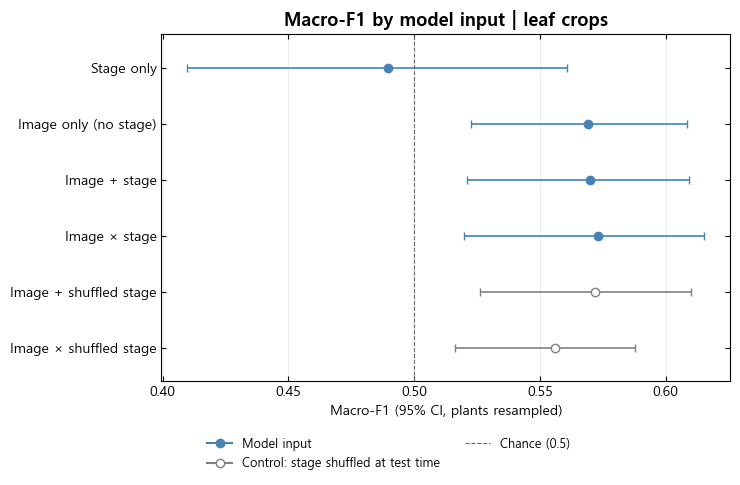

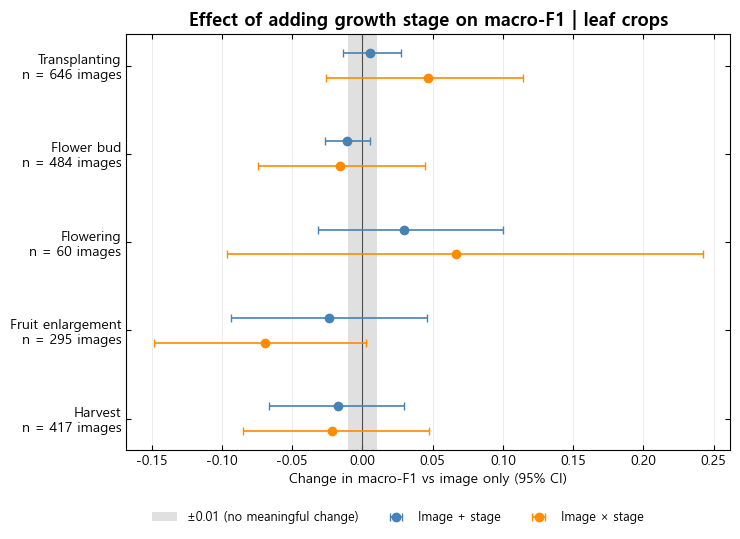

no_stage macro-F1 0.569  (95% CI 0.523-0.609)
Baseline still near chance -> ignore the DECISION line; the stage comparison can't be judged on this data.
Figures saved in: ablation_out_leafcrop


In [21]:
plot_by_input(overall, "Macro-F1 by model input | leaf crops", OUT / "ablation_by_input.png")
plot_by_stage(boot_stage, "Effect of adding growth stage on macro-F1 | leaf crops", OUT / "ablation_by_stage.png")

b = overall.set_index("arm").loc["no_stage"]
print(f"no_stage macro-F1 {b.macro_f1:.3f}  (95% CI {b.ci_lo:.3f}-{b.ci_hi:.3f})")
if b.ci_lo > 0.6:
    print("Baseline clearly above chance -> the stage comparison is interpretable. Use the DECISION line.")
else:
    print("Baseline still near chance -> ignore the DECISION line; the stage comparison can't be judged on this data.")
print("Figures saved in:", OUT.resolve())